# IPL six-rate forecasting

Executed results companion, 14 October 2026. The question is whether recent form helps forecast future sixes without overreacting to noise. Read `docs/SIXES_REPORT.md` for interpretation and limitations. These evaluation years were previously examined during outcome exploration.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
out = root / 'results/sixes'
print(json.loads((out / 'data_audit.json').read_text()))

{'raw_events': 295732, 'all_position_legal_balls': 284465, 'top7_legal_balls': 267994, 'sixes': 14916, 'min_date': '2008-04-18', 'max_date': '2026-05-31', 'matches': 1243, 'players': 495, 'source_sha256': '5757e04287179767ff8495f02902bd13812b9572ec8fa2ac1347ec2e9c6d4709'}


## The three probability forecasts

Population uses comparable batting positions. Raw uses the player’s observed rate. Empirical Bayes shrinks the personal rate towards its fitted population. Every success is a six off the bat on an eligible legal delivery; non-sixes remain zeroes.

## Early-to-late within season

Lower scores are better. Model selection used 2024 only. Raw probabilities are clipped only for log scoring.

In [2]:
display(pd.read_csv(out / 'brown_metrics.csv').query('period == "evaluation"'))
display(pd.read_csv(out / 'brown_uncertainty.csv'))

,model,N,B,players,log_loss,brier,player_macro_log_loss,player_macro_brier,period
6,population,12881,1153,124,0.302056,0.081586,0.289807,0.077285,evaluation
7,raw,12881,1153,124,0.381970,0.082318,0.382756,0.078341,evaluation
8,shrinkage,12881,1153,124,0.300497,0.081276,0.289121,0.077134,evaluation


,model,reference,unit,N,date_blocks,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high,skill_pct,skill_low,skill_high
0,shrinkage,population,date,12881,54,-0.001559,-0.003279,0.000088,-0.000310,-0.000652,-0.000008,0.516075,-0.028647,1.086578
1,shrinkage,raw,date,12881,54,-0.081473,-0.113873,-0.052521,-0.001042,-0.001490,-0.000629,21.329775,14.682122,27.411190


## Forecasting the next innings

Lower scores are better. Model selection used 2024 only. Raw probabilities are clipped only for log scoring.

In [3]:
display(pd.read_csv(out / 'sequential_metrics.csv').query('period == "evaluation"'))
display(pd.read_csv(out / 'sequential_uncertainty.csv'))

,model,N,B,players,log_loss,brier,player_macro_log_loss,player_macro_brier,period
16,population,30980,2591,141,0.289370,0.076874,0.267594,0.069776,evaluation
17,raw_expanding,30980,2591,141,0.322573,0.077134,0.351903,0.070735,evaluation
18,expanding,30980,2591,141,0.287087,0.076460,0.265428,0.069416,evaluation
19,rolling_300,30980,2591,141,0.286402,0.076388,0.265130,0.069386,evaluation
20,ew_balls_300,30980,2591,141,0.286420,0.076392,0.265051,0.069373,evaluation
21,raw_recent,30980,2591,141,0.323310,0.077260,0.352097,0.070769,evaluation
22,rolling_30,30980,2591,141,0.288363,0.076709,0.265805,0.069487,evaluation
23,current,30980,2591,141,0.286726,0.076452,0.265619,0.069474,evaluation


,model,reference,unit,N,date_blocks,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high,skill_pct,skill_low,skill_high
0,ew_balls_300,expanding,date,30980,124,-0.000667,-0.001021,-0.000325,-0.000068,-0.000111,-0.000027,0.232293,0.115016,0.351337
1,rolling_300,current,date,30980,124,-0.000324,-0.001112,0.000478,-0.000065,-0.000177,0.000051,0.113085,-0.167681,0.382755
2,rolling_300,expanding,date,30980,124,-0.000686,-0.001289,-0.000132,-0.000073,-0.000151,0.000004,0.238799,0.045936,0.443237
3,rolling_300,population,date,30980,124,-0.002969,-0.004616,-0.001432,-0.000487,-0.000747,-0.000242,1.025861,0.501891,1.577052
4,rolling_300,raw_expanding,date,30980,124,-0.036172,-0.048423,-0.024576,-0.000746,-0.001077,-0.000426,11.213483,7.894303,14.565778
5,rolling_300,raw_recent,date,30980,124,-0.036908,-0.049320,-0.025171,-0.000873,-0.001266,-0.000519,11.415776,7.997257,14.834163
6,rolling_300,rolling_30,date,30980,124,-0.001962,-0.003040,-0.000991,-0.000321,-0.000500,-0.000160,0.680248,0.345443,1.044278
7,rolling_300,expanding,player,30980,124,-0.000686,-0.001553,0.000072,-0.000073,-0.000184,0.000021,0.238799,-0.025259,0.524264


## Forecasting a whole next season

Lower scores are better. Model selection used 2024 only. Raw probabilities are clipped only for log scoring.

In [4]:
display(pd.read_csv(out / 'preseason_metrics.csv').query('period == "evaluation"'))
display(pd.read_csv(out / 'preseason_uncertainty.csv'))

,model,N,B,players,log_loss,brier,player_macro_log_loss,player_macro_brier,period
14,population,30980,2591,141,0.288902,0.076816,0.267251,0.069725,evaluation
15,raw_expanding,30980,2591,141,0.300463,0.076751,0.305469,0.069738,evaluation
16,expanding,30980,2591,141,0.287609,0.076568,0.265753,0.069472,evaluation
17,rolling_120,30980,2591,141,0.287921,0.076624,0.265828,0.069493,evaluation
18,ew_balls_1200,30980,2591,141,0.287388,0.076546,0.265637,0.069460,evaluation
19,raw_recent,30980,2591,141,0.302505,0.077012,0.306277,0.069849,evaluation
20,rolling_30,30980,2591,141,0.288611,0.076743,0.266181,0.069535,evaluation


,model,reference,unit,N,date_blocks,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high,skill_pct,skill_low,skill_high
0,ew_balls_1200,expanding,date,30980,124,-0.000220,-0.000331,-0.000116,-0.000022,-0.000034,-0.000009,0.076529,0.040737,0.113382
1,rolling_120,expanding,date,30980,124,0.000312,-0.000382,0.000965,0.000056,-0.000034,0.000144,-0.108555,-0.336102,0.131622
2,rolling_120,population,date,30980,124,-0.000981,-0.002130,0.000144,-0.000192,-0.000368,-0.000018,0.339527,-0.048951,0.732115
3,rolling_120,raw_expanding,date,30980,124,-0.012542,-0.019623,-0.006364,-0.000126,-0.000322,0.000050,4.174304,2.151111,6.448640
4,rolling_120,raw_recent,date,30980,124,-0.014585,-0.021856,-0.008355,-0.000388,-0.000568,-0.000218,4.821283,2.824832,7.111557
5,rolling_120,rolling_30,date,30980,124,-0.000690,-0.001472,0.000064,-0.000118,-0.000248,0.000002,0.239006,-0.022310,0.508203
6,rolling_120,expanding,player,30980,124,0.000312,-0.000949,0.001573,0.000056,-0.000113,0.000232,-0.108555,-0.551579,0.329583


## What does this say about genuine improvement?

A modest simple-forecast gain is useful evidence, but player-cluster uncertainty and the context check weaken a permanent-improvement claim. Very short histories lose; not every use of a shorter history loses. The selected preseason rule underperforms full history.

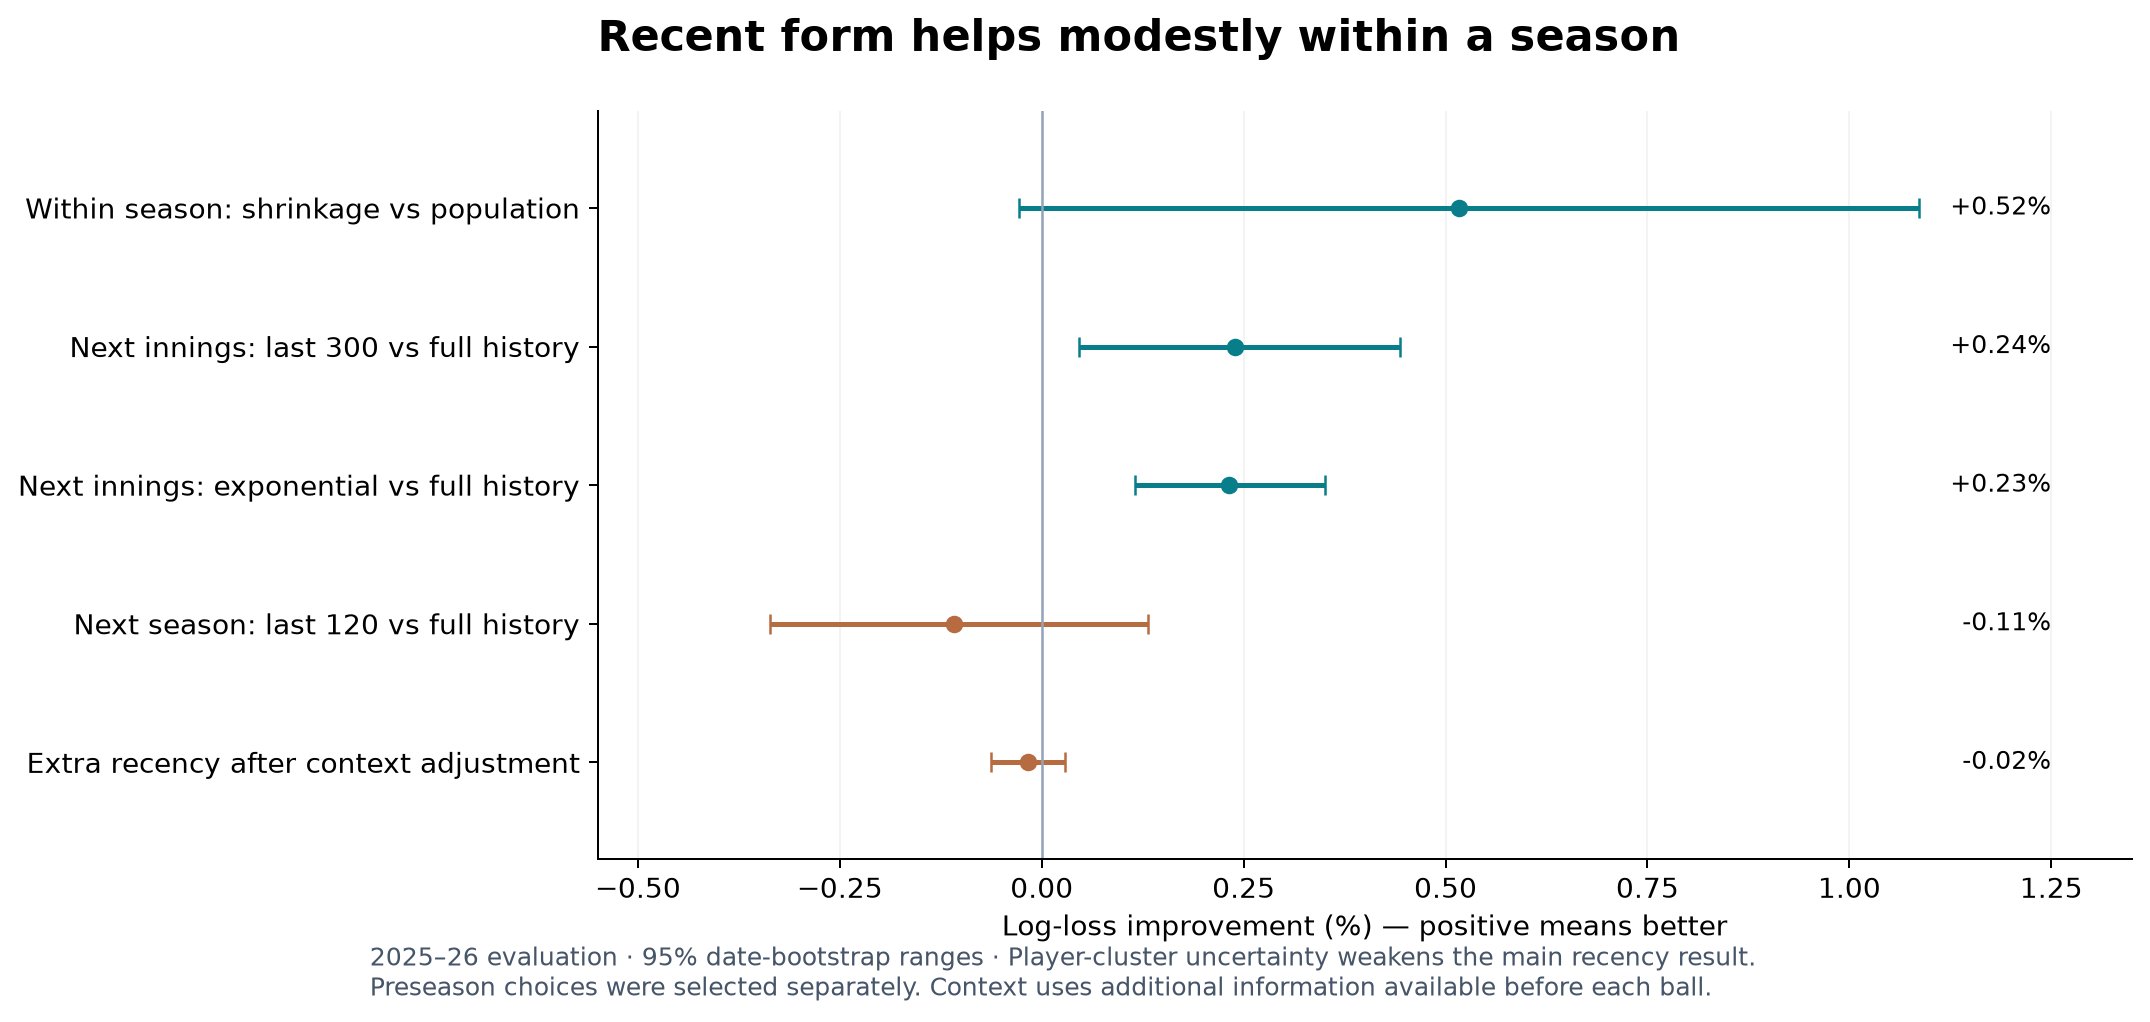

,model,N,B,players,log_loss,brier,player_macro_log_loss,player_macro_brier
0,context,30980,2591,141,0.283560,0.076152,0.264816,0.069586
1,context_recent,30980,2591,141,0.283608,0.076174,0.265003,0.069643


,model,reference,unit,N,date_blocks,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high,skill_pct,skill_low,skill_high
0,context_recent,context,date,30980,124,0.000048,-0.00008,0.000176,0.000022,-0.000003,0.000047,-0.01695,-0.062573,0.028537


In [5]:
display(Image(filename=str(root / 'figures/sixes/evidence.png')))
display(pd.read_csv(out / 'context_metrics.csv'))
display(pd.read_csv(out / 'context_uncertainty.csv'))

## Temporary-form examples

These cases were selected retrospectively from all early-data spike flags. Their later reversion does not prove luck caused the spike.

,player,batter_id,season,role,cutoff_date,prior_N,early_N,early_B,late_N,late_B,baseline,early_rate,early_only_shrinkage,history_retaining_shrinkage,late_rate,early_excess,reversion_example
0,SS Iyer,85ec8e33,2026,4,2026-04-29,868,175,22,82,5,0.049076,0.125714,0.106923,0.060972,0.060976,0.076638,True
1,SV Samson,a4cc73aa,2022,3,2022-04-27,1354,77,10,169,8,0.059457,0.129870,0.080897,0.062984,0.047337,0.070413,True
2,Ishan Kishan,752f7486,2024,0,2024-04-23,1017,114,13,85,3,0.052657,0.114035,0.062705,0.057116,0.035294,0.061378,True


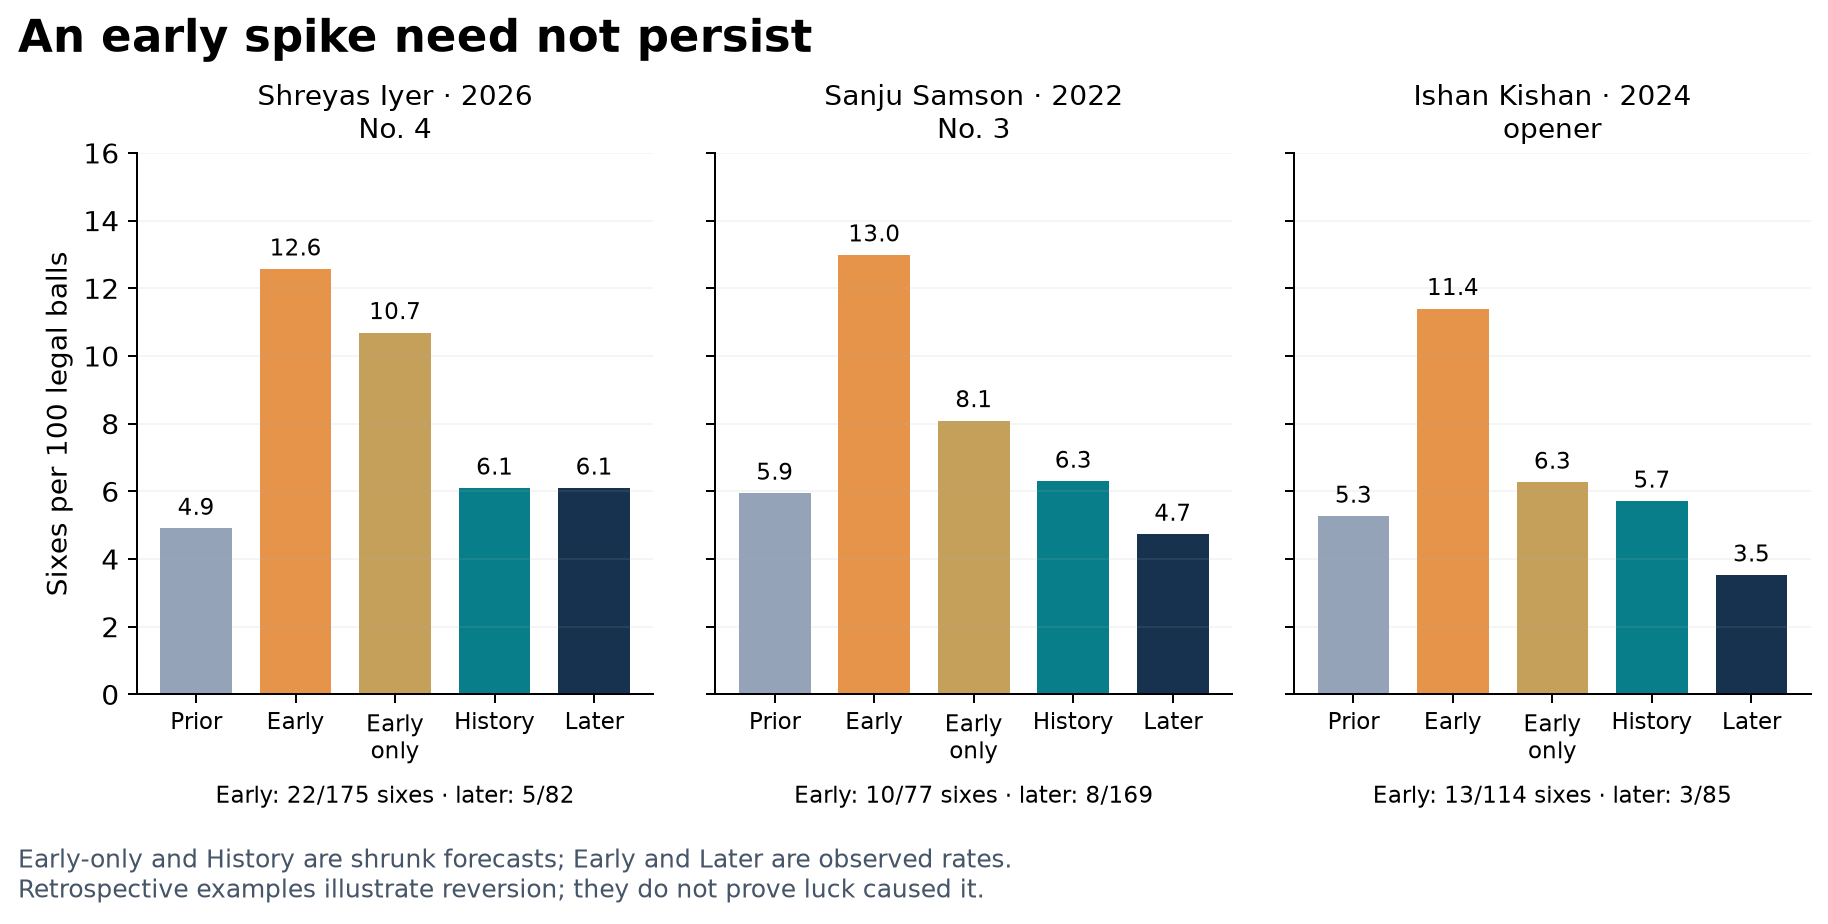

In [6]:
display(pd.read_csv(out / 'temporary_form_cases.csv'))
display(Image(filename=str(root / 'figures/sixes/temporary_form.png')))

## Conditional 2027 forecasts

Expected sixes per 100 legal balls, assuming the 2026 role mix. Stability ranges exclude model-selection uncertainty, availability and new regimes. Compare the full-history alternative; the selected short-history preseason rule did not beat it in later evaluation.

,player,latest_N,latest_rate,forecast,forecast_low,forecast_high,full_history_forecast
0,RG Sharma,179,0.117318,0.101998,0.073056,0.126883,0.063063
1,AM Rahane,248,0.072581,0.065774,0.046934,0.086440,0.031238
2,Ishan Kishan,330,0.096970,0.099683,0.076148,0.134703,0.080300
3,TM Head,240,0.095833,0.117867,0.074372,0.158098,0.090262
4,Shubman Gill,449,0.073497,0.070260,0.057285,0.085403,0.048745
5,Abhishek Sharma,275,0.156364,0.112578,0.075353,0.150083,0.102726
6,JC Buttler,345,0.075362,0.097598,0.075242,0.116987,0.074931
7,SS Iyer,293,0.102389,0.073483,0.053916,0.090749,0.061763


,player,latest_N,latest_rate,forecast,forecast_low,forecast_high,full_history_forecast
0,N Pooran,182,0.104396,0.112084,0.082102,0.137771,0.118445
1,H Klaasen,390,0.079487,0.089797,0.075344,0.102668,0.085227
2,C Green,220,0.077273,0.080993,0.066126,0.094884,0.080177
3,Dhruv Jurel,333,0.072072,0.079162,0.062372,0.097504,0.074598
4,N Rana,149,0.067114,0.079162,0.061965,0.095244,0.069787
5,A Raghuvanshi,287,0.066202,0.077793,0.050890,0.107234,0.069608
6,R Tewatia,131,0.061069,0.073212,0.063765,0.084860,0.067161
7,RK Singh,197,0.055838,0.072979,0.064144,0.082449,0.071077


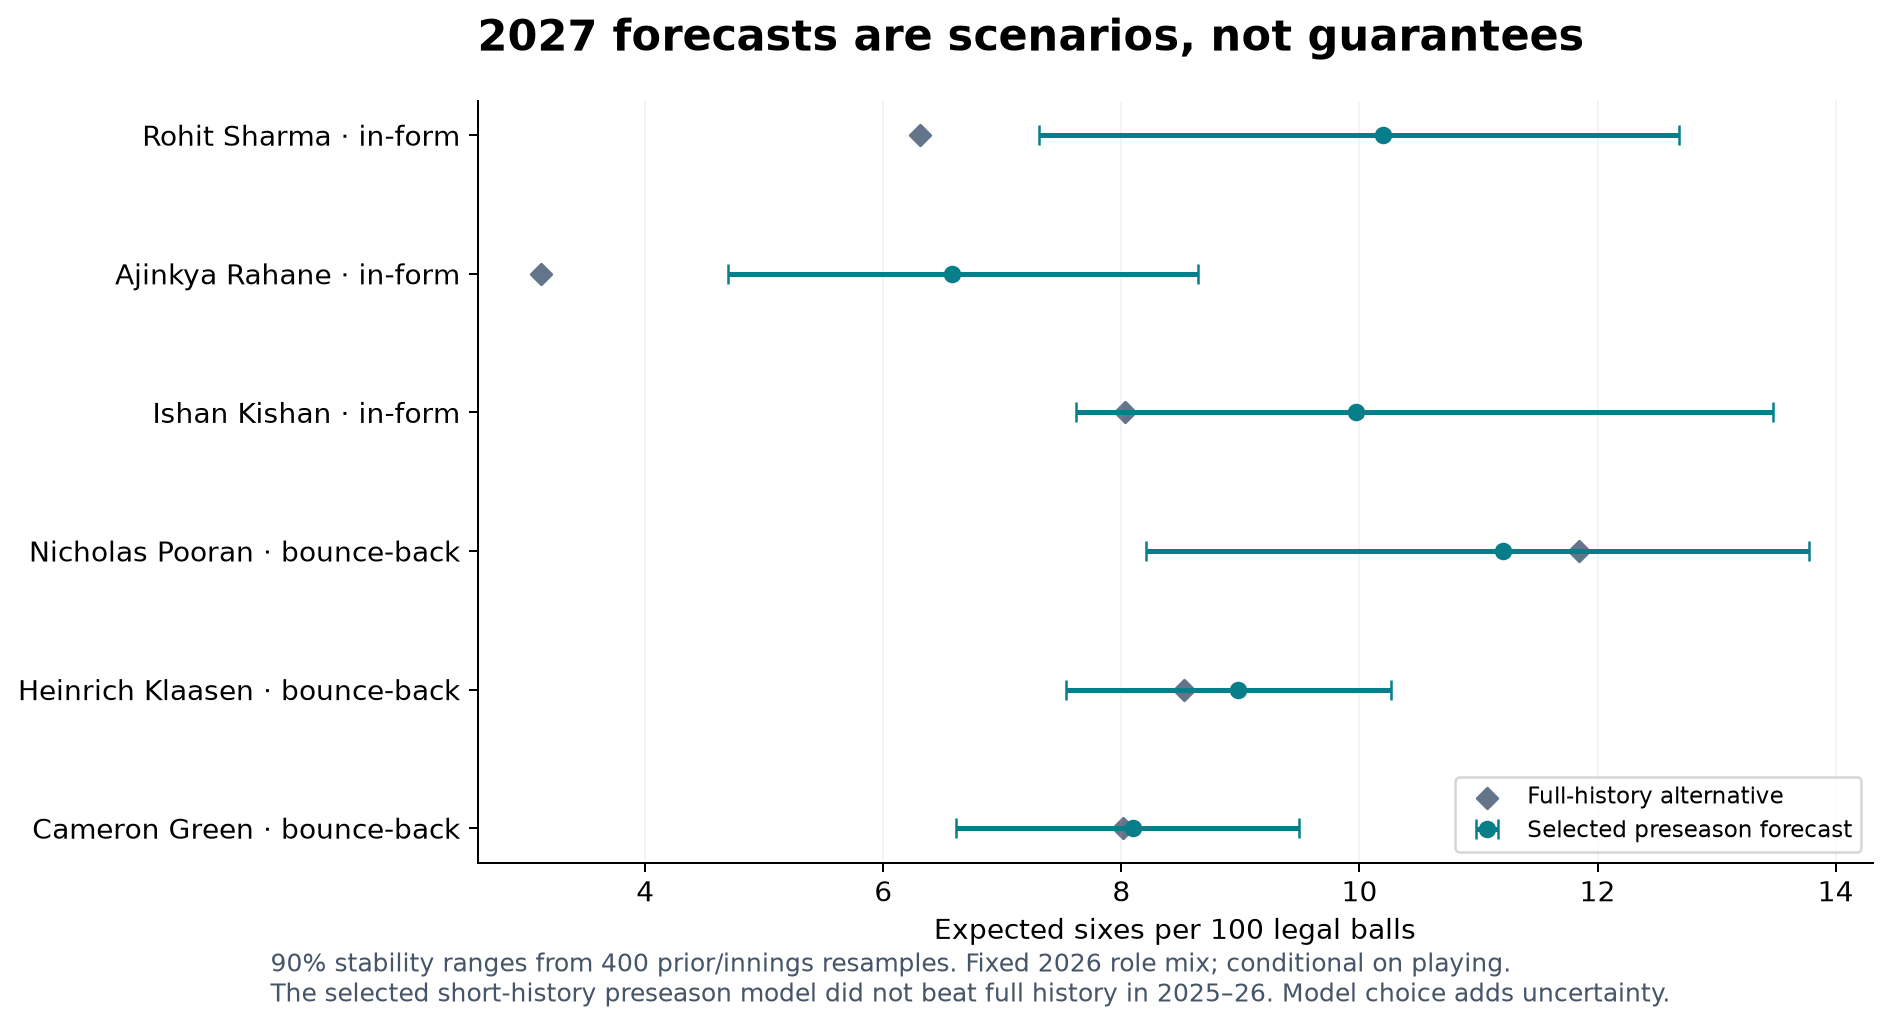

In [7]:
cols = ['player','latest_N','latest_rate','forecast','forecast_low','forecast_high','full_history_forecast']
display(pd.read_csv(out / 'watchlist_in_form.csv')[cols].head(8))
display(pd.read_csv(out / 'watchlist_bounce_back.csv')[cols].head(8))
display(Image(filename=str(root / 'figures/sixes/forecasts.png')))

In [8]:
verification = json.loads((root / 'reports/sixes_verification.json').read_text())
assert verification['passed']
for check in verification['checks']:
    print('PASS:', check)

PASS: Every six and legal opportunity independently reconstructed from original JSON, including opening roles and source non-boundary flags
PASS: All earlier research outputs and source files remain byte-identical
PASS: All history timestamps strictly precede prediction dates; 150 full memory vectors agree with independent direct snapshots
PASS: Annual population priors use only preceding three complete seasons and correct player-role pooled counts
PASS: Selection uses 2024 only; identical evaluation targets, all published scores and paired point estimates independently verified
PASS: Within-season six forecasts at positions 3–7 reproduce the previously committed outcome study to 1e-10
PASS: Every preseason role mixture is built from completed past seasons only, including debutant fallback
PASS: Context encoders, coefficients and historical recency-feature choices are past-only and converge
PASS: Every dated 2027 role forecast and player mixture independently reconstructed; uncertainty